In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
df = pd.read_csv(r"C:\Users\91982\Downloads\house_price_prediction.csv")

df.head()

,House_ID,Area_sqft,Bedrooms,Bathrooms,House_Age,Distance_City_km,Price_INR
0,1001,3419,1,1,23,9,13583193
1,1002,1714,2,2,21,24,6819729
2,1003,1156,5,5,1,1,7629323
3,1004,1695,2,2,17,7,7519400
4,1005,3461,5,5,7,15,16880144


In [3]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
print(df.info())

Dataset Shape: (100, 7)

Column Names:
['House_ID', 'Area_sqft', 'Bedrooms', 'Bathrooms', 'House_Age', 'Distance_City_km', 'Price_INR']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   House_ID          100 non-null    int64
 1   Area_sqft         100 non-null    int64
 2   Bedrooms          100 non-null    int64
 3   Bathrooms         100 non-null    int64
 4   House_Age         100 non-null    int64
 5   Distance_City_km  100 non-null    int64
 6   Price_INR         100 non-null    int64
dtypes: int64(7)
memory usage: 5.6 KB
None


In [4]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
House_ID            0
Area_sqft           0
Bedrooms            0
Bathrooms           0
House_Age           0
Distance_City_km    0
Price_INR           0
dtype: int64


In [5]:

X = df[
    [
        'Area_sqft',
        'Bedrooms',
        'Bathrooms',
        'House_Age',
        'Distance_City_km'
    ]
]

y = df['Price_INR']

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (80, 5)
Testing data: (20, 5)


In [7]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [8]:
print("Intercept:", model.intercept_)

print("\nCoefficients:")

for feature, coefficient in zip(X.columns, model.coef_):
    print(feature, ":", coefficient)

Intercept: 1363.7802881225944

Coefficients:
Area_sqft : 4222.5341915511935
Bedrooms : 395516.4551138034
Bathrooms : 209244.62058129426
House_Age : -45933.97086004692
Distance_City_km : -32020.939281784813


In [9]:
y_pred = model.predict(X_test)

print("Predicted Prices:")
print(y_pred[:10])

Predicted Prices:
[ 8014175.46785812  7057091.77229885  7991147.7927116   6788323.12918904
 12037094.90754381  8441479.82185997  7596715.47079173  3578335.9414641
 13820589.47868698 13698299.47357961]


In [10]:
comparison = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred
})

print(comparison)

    Actual Price  Predicted Price
0        8022519     8.014175e+06
1        7131369     7.057092e+06
2        7951382     7.991148e+06
3        6692932     6.788323e+06
4       12072950     1.203709e+07
5        8540500     8.441480e+06
6        7693417     7.596715e+06
7        3614657     3.578336e+06
8       13703284     1.382059e+07
9       13583193     1.369830e+07
10      11983303     1.211136e+07
11       4800198     4.729283e+06
12       7908836     8.051386e+06
13       8720586     8.733377e+06
14       8078967     8.181062e+06
15      16880144     1.683751e+07
16      11878876     1.195788e+07
17       4329596     4.455993e+06
18      12014242     1.214540e+07
19       6757784     6.709977e+06


In [11]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Model Evaluation")
print("-------------------------")
print("MAE  :", mae)
print("MSE  :", mse)
print("RMSE :", rmse)
print("R² Score:", r2)

Model Evaluation
-------------------------
MAE  : 80074.80761545226
MSE  : 8044851140.626696
RMSE : 89693.0941635235
R² Score: 0.9992975368249626


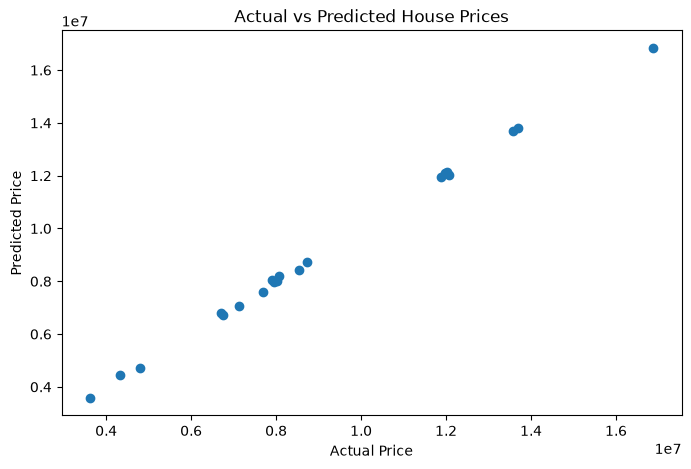

In [12]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")

plt.title("Actual vs Predicted House Prices")

plt.show()

In [13]:
import joblib

joblib.dump(model, "house_price_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [14]:
import tkinter as tk
from tkinter import messagebox
import numpy as np


# Function to predict house price
def predict_price():

    try:
        # Get values from GUI
        area = float(entry_area.get())
        bedrooms = float(entry_bedrooms.get())
        bathrooms = float(entry_bathrooms.get())
        house_age = float(entry_age.get())
        distance = float(entry_distance.get())

        # Create input array
        input_data = np.array([
            [area, bedrooms, bathrooms, house_age, distance]
        ])

        # Predict price
        prediction = model.predict(input_data)

        # Get predicted price
        predicted_price = prediction[0]

        # Display result
        result_label.config(
            text=f"Predicted House Price: ₹{predicted_price:,.2f}"
        )

    except ValueError:
        messagebox.showerror(
            "Invalid Input",
            "Please enter valid numerical values."
        )

    except Exception as e:
        messagebox.showerror(
            "Error",
            f"Something went wrong:\n{e}"
        )


# Create main window
root = tk.Tk()

root.title("House Price Prediction")
root.geometry("500x500")


# Heading
title_label = tk.Label(
    root,
    text="House Price Prediction",
    font=("Arial", 20, "bold")
)

title_label.pack(pady=20)


# Area
tk.Label(
    root,
    text="Area (sqft)",
    font=("Arial", 12)
).pack()

entry_area = tk.Entry(root, width=30)
entry_area.pack(pady=5)


# Bedrooms
tk.Label(
    root,
    text="Number of Bedrooms",
    font=("Arial", 12)
).pack()

entry_bedrooms = tk.Entry(root, width=30)
entry_bedrooms.pack(pady=5)


# Bathrooms
tk.Label(
    root,
    text="Number of Bathrooms",
    font=("Arial", 12)
).pack()

entry_bathrooms = tk.Entry(root, width=30)
entry_bathrooms.pack(pady=5)


# House Age
tk.Label(
    root,
    text="House Age (years)",
    font=("Arial", 12)
).pack()

entry_age = tk.Entry(root, width=30)
entry_age.pack(pady=5)


# Distance from city
tk.Label(
    root,
    text="Distance from City (km)",
    font=("Arial", 12)
).pack()

entry_distance = tk.Entry(root, width=30)
entry_distance.pack(pady=5)


# Prediction button
predict_button = tk.Button(
    root,
    text="Predict House Price",
    command=predict_price,
    font=("Arial", 12, "bold")
)

predict_button.pack(pady=20)


# Result
result_label = tk.Label(
    root,
    text="Predicted House Price: ₹0.00",
    font=("Arial", 14, "bold")
)

result_label.pack(pady=10)


# Run GUI
root.mainloop()